In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

from qss.solver_options import brent_defaults, sa_defaults
from qss.chemical_potential import chemical_potential
from qss.distributions import DistType, prepare_2D_lattice_data

In [2]:
MU_B  = 5.788381806e-5  # eV/T
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(-np.pi, np.pi, N, endpoint=False)
ky = np.linspace(-np.pi, np.pi, N, endpoint=False)
e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

In [3]:
# Band filling values
n_min = 0.1
n_max = 0.99
n_count = 10

# Magnetic field values
Ha_min = 0.0
Ha_max = 10.0
Ha_count = 5

# Beta values

beta_min = -2
beta_max = 4
beta_count = 120

distros = [DistType.FD, DistType.FLB, DistType.NFLB]  # ND
# n  = np.array([0.5, 0.8, 0.9], dtype=np.float64)  # NN
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
# beta = np.array([0.1, 1.0], dtype=np.float64)  # NB
beta = np.logspace(beta_min, beta_max, beta_count, dtype=np.float64)  # NB
H_a = np.array([0.0], dtype=np.float64) # NH
# H_a = np.linspace(Ha_min, Ha_max, Ha_count, dtype=np.float64) # NH

In [4]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=1.4,
    initial_step=10.0,  
    max_expands=64,
    max_iters=5000      
)
native_opts= py_opts.to_qss()

In [5]:
# py_opts = sa_defaults(T0=5e3,
#                       T_min=1e-8,
#                       alpha=0.95,
#                       max_iters=1e6,
#                       min_iters = 105,
#                       stall_iters=60,
#                       step_decay=1.1,
#                       step_sigma=2.35,
#                       bounds=[(-3., 3.)]
#                       )
# native_opts= py_opts.to_qss()

In [6]:
mu_df = chemical_potential(
    distros=["FD", "FLB", "NFLB"],
    n_vals=n,
    beta_vals=beta,
    H_a_vals=H_a,
    N=N,
    E=e_k,
    solver_opts=native_opts,
    x0=10.,
    a0=-5.0,
    b0=5.0,
)
mu_df.to_csv("chemical_potential_results.csv")
mu_df

mu  iterations  converged      residual
distro n        k_BT     H_a                                                 
FD     0.100000 100.0000 0.0 -294.454038          23       True  1.448324e-08
       0.198889 100.0000 0.0 -220.350260          23       True  4.282753e-08
       0.297778 100.0000 0.0 -174.342155          21       True  4.500254e-08
       0.396667 100.0000 0.0 -139.681179          23       True  4.507172e-08
       0.495556 100.0000 0.0 -111.055642          22       True  6.504577e-08
...                                  ...         ...        ...           ...
NFLB   0.594444 0.0001   0.0    0.289433          26       True  5.180048e-08
       0.693333 0.0001   0.0    0.755787          23       True  3.936619e-07
       0.792222 0.0001   0.0    1.345461          22       True  1.217815e-11
       0.891111 0.0001   0.0    2.051694          24       True  3.306553e-08
       0.990000 0.0001   0.0    2.905516          22       True  3.287814e-07

[3600 rows x 4 columns]

(-3.0, 3.0)

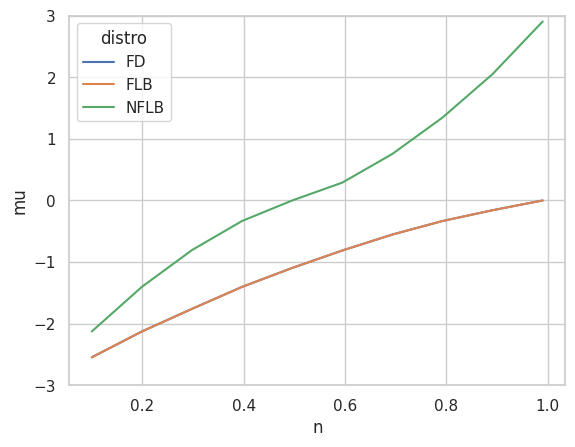

In [7]:
data = mu_df.loc[(["FD","FLB","NFLB"], n, 1/beta[-1], H_a[0]), :]
fig,ax = plt.subplots()
sns.lineplot(data= data, x="n", y="mu", hue="distro", markers=True, ax=ax)
ax.set_ylim(-3,3)

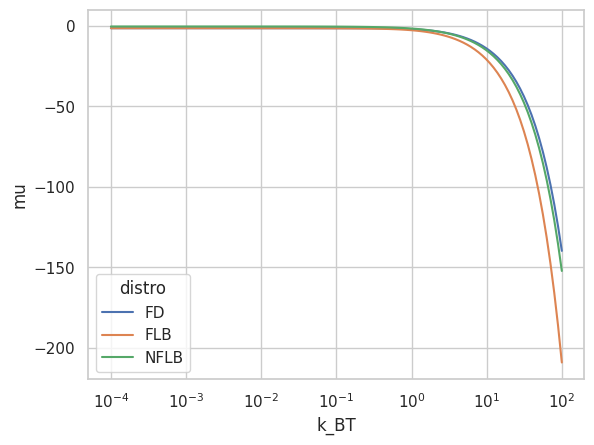

In [8]:
data = mu_df.loc[(["FD","FLB", "NFLB"], n[-7], 1/beta, H_a[0]), :]  # Series with MultiIndex (dist, n)

fig,ax = plt.subplots()
sns.lineplot(data= data, x="k_BT", y="mu", hue="distro", markers=True, ax=ax)
ax.set_xscale("log")